<a href="https://colab.research.google.com/github/FadhilTaufiqurrachman/Machine-Learning/blob/main/244107020090_Fadhil_Taufiqurrachman_P13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Jobsheet 13 - Artificial Neural Network (ANN) Dan Evaluasi Classifier

NIM : 244107020090

Nama : Fadhil Taufiqurrachman

Kelas : TI 3G

No Absen : 06

Mata Kuliah : Pembelajaran Mesin

Menyiapkan Data

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')
BASE_PATH = '/content/drive/MyDrive/Education/Current Semester College File /Machine Learning/'

Mounted at /content/drive


### Praktikum 1

Langkah 1 - Buat Dataset Sederhana (XOR)

In [ ]:
import numpy as np

# Dataset XOR
# 4 baris data, masing-masing memiliki 2 fitur (input)
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])

# Target output (label) dari masing-masing baris input
y = np.array([[0], [1], [1], [0]])

print("Data Input (X):\n", X)
print("\nTarget Output (y):\n", y)

Data Input (X):
 [[0 0]
 [0 1]
 [1 0]
 [1 1]]

Target Output (y):
 [[0]
 [1]
 [1]
 [0]]


Langkah 2 - Inisialisasi Bobot Dan Bias

In [ ]:
# Parameter Jaringan
input_size = 2
hidden_size = 2
output_size = 1
lr = 0.1  # Learning rate: seberapa besar model mengupdate bobot dalam sekali iterasi

# Inisialisasi bobot dan bias secara acak menggunakan distribusi normal
np.random.seed(42) # Ditambahkan seed agar nilai acaknya tetap konsisten saat run ulang

# Layer 1 (Input ke Hidden Layer)
W1 = np.random.randn(input_size, hidden_size)
b1 = np.zeros((1, hidden_size))

# Layer 2 (Hidden Layer ke Output Layer)
W2 = np.random.randn(hidden_size, output_size)
b2 = np.zeros((1, output_size))

# Definisi Fungsi Aktivasi
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Fungsi turunan Sigmoid (digunakan untuk menghitung gradien error)
def sigmoid_derivative(x):
    return x * (1 - x)

print("Arsitektur berhasil diinisialisasi!")
print(f"Bentuk W1: {W1.shape}, Bentuk W2: {W2.shape}")

Arsitektur berhasil diinisialisasi!
Bentuk W1: (2, 2), Bentuk W2: (2, 1)


Langkah 3 - Proses Training

In [ ]:
# Training Loop
for epoch in range(10000):

    # ----------------------------------------------------
    # Implementasikan forward pass
    # ----------------------------------------------------
    # Perambatan maju dari Input ke Hidden Layer
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1) # Hasil aktivasi Hidden Layer

    # Perambatan maju dari Hidden Layer ke Output
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2) # Prediksi akhir (output jaringan)

    # ----------------------------------------------------
    # Hitung error dan lakukan backpropagation
    # ----------------------------------------------------
    # Hitung selisih antara target sebenarnya (y) dengan prediksi (a2)
    error = y - a2

    # Backpropagation Layer 2 (Output)
    # Menghitung seberapa besar W2 dan b2 menyumbang kesalahan
    d_a2 = error * sigmoid_derivative(a2)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    # Backpropagation Layer 1 (Hidden)
    # Menyebarkan error mundur untuk menghitung kesalahan dari W1 dan b1
    d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # ----------------------------------------------------
    # Update bobot menggunakan gradient descent
    # ----------------------------------------------------
    # Memperbarui bobot agar di iterasi berikutnya error semakin kecil
    W1 += lr * d_W1
    b1 += lr * d_b1
    W2 += lr * d_W2
    b2 += lr * d_b2

    # Tampilkan evaluasi (Mean Squared Error) setiap 1000 epoch
    if epoch % 1000 == 0:
        loss = np.mean(np.square(error))
        print(f"Epoch {epoch}, Loss: {loss:.6f}")

# Output akhir setelah jaringan selesai belajar
print("\nTarget Sebenarnya (y):")
print(y)
print("\nPrediksi Akhir (a2) setelah 10000 Epoch:")
print(a2)

Epoch 0, Loss: 0.255830
Epoch 1000, Loss: 0.249406
Epoch 2000, Loss: 0.245445
Epoch 3000, Loss: 0.204707
Epoch 4000, Loss: 0.153204
Epoch 5000, Loss: 0.138691
Epoch 6000, Loss: 0.133594
Epoch 7000, Loss: 0.131151
Epoch 8000, Loss: 0.129749
Epoch 9000, Loss: 0.128849

Target Sebenarnya (y):
[[0]
 [1]
 [1]
 [0]]

Prediksi Akhir (a2) setelah 10000 Epoch:
[[0.05300868]
 [0.49554213]
 [0.95091319]
 [0.50319888]]


### Tugas 1

Langkah 1 - Ubah Jumlah Neuron Hidden Layer Menjadi 3

In [ ]:
print("=== Skenario 1: Hidden Layer = 3 Neuron, Aktivasi = Sigmoid ===\n")

# 1. Update Parameter Jaringan
input_size = 2
hidden_size_tugas1 = 3  # Diubah dari 2 menjadi 3
output_size = 1
lr = 0.1

# Inisialisasi ulang bobot dan bias dengan dimensi baru
np.random.seed(42) # Seed untuk konsistensi komparasi
W1_3n = np.random.randn(input_size, hidden_size_tugas1)
b1_3n = np.zeros((1, hidden_size_tugas1))
W2_3n = np.random.randn(hidden_size_tugas1, output_size)
b2_3n = np.zeros((1, output_size))

# 2. Training Loop
for epoch in range(10000):
    # Forward pass
    z1 = np.dot(X, W1_3n) + b1_3n
    a1 = sigmoid(z1) # Masih menggunakan sigmoid peninggalan praktikum 1

    z2 = np.dot(a1, W2_3n) + b2_3n
    a2 = sigmoid(z2)

    # Hitung error
    error = y - a2

    # Backpropagation
    d_a2 = error * sigmoid_derivative(a2)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2_3n.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Update bobot
    W1_3n += lr * d_W1
    b1_3n += lr * d_b1
    W2_3n += lr * d_W2
    b2_3n += lr * d_b2

    if epoch == 9999: # Ambil loss di epoch terakhir untuk komparasi
        loss_sigmoid_3n = np.mean(np.square(error))

print(f"Loss akhir (10000 epoch) dengan 3 Neuron (Sigmoid): {loss_sigmoid_3n:.6f}")
print("Prediksi Akhir:")
print(a2)

=== Skenario 1: Hidden Layer = 3 Neuron, Aktivasi = Sigmoid ===

Loss akhir (10000 epoch) dengan 3 Neuron (Sigmoid): 0.002297
Prediksi Akhir:
[[0.02515564]
 [0.95263635]
 [0.95122343]
 [0.0627247 ]]


Langkah 2 - Bandingkan Hasil Loss Dengan Konfigurasi Awal

Menambah neuron pada hidden layer dari 2 menjadi 3 memberikan jaringan "kapasitas memori" dan fleksibilitas lebih besar untuk membentuk batas keputusan (decision boundary) yang non-linear. Loss pada konfigurasi 3 neuron lebih kecil (lebih baik) dibandingkan 2 neuron pada jumlah epoch yang sama. Jaringan menjadi lebih cepat konvergen (mengenali pola XOR) karena memiliki lebih banyak fitur ekstraksi di lapisan tersembunyi.

Langkah 3 - Tambahkan Fungsi Aktivasi ReLU Dan Bandingkan Hasil

In [ ]:
print("=== Skenario 2: Hidden Layer = 3 Neuron, Aktivasi = ReLU ===\n")

# 1. Definisi Fungsi Aktivasi ReLU dan Turunannya
def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    # Turunan ReLU: 1 jika x > 0, 0 jika x <= 0
    return np.where(x > 0, 1, 0)

# Inisialisasi ulang bobot dan bias dari awal agar adil
np.random.seed(42)
W1_relu = np.random.randn(input_size, hidden_size_tugas1)
b1_relu = np.zeros((1, hidden_size_tugas1))
W2_relu = np.random.randn(hidden_size_tugas1, output_size)
b2_relu = np.zeros((1, output_size))

# 2. Training Loop
for epoch in range(10000):
    # Forward pass
    z1 = np.dot(X, W1_relu) + b1_relu
    a1 = relu(z1) # MENGGUNAKAN RELU DI HIDDEN LAYER

    z2 = np.dot(a1, W2_relu) + b2_relu
    a2 = sigmoid(z2) # Output layer tetap Sigmoid untuk klasifikasi biner

    # Hitung error
    error = y - a2

    # Backpropagation
    # Output layer (Sigmoid derivative)
    d_a2 = error * sigmoid_derivative(a2)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    # Hidden layer (ReLU derivative)
    # Perhatikan kita menggunakan relu_derivative di baris ini
    d_a1 = np.dot(d_a2, W2_relu.T) * relu_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Update bobot
    W1_relu += lr * d_W1
    b1_relu += lr * d_b1
    W2_relu += lr * d_W2
    b2_relu += lr * d_b2

    if epoch == 9999:
        loss_relu_3n = np.mean(np.square(error))

print(f"Loss akhir (10000 epoch) dengan 3 Neuron (ReLU): {loss_relu_3n:.6f}")
print("Prediksi Akhir:")
print(a2)

=== Skenario 2: Hidden Layer = 3 Neuron, Aktivasi = ReLU ===

Loss akhir (10000 epoch) dengan 3 Neuron (ReLU): 0.000352
Prediksi Akhir:
[[0.02970009]
 [0.98605912]
 [0.98605934]
 [0.01163533]]


Kecepatan: ReLU (max(0, x)) sangat ringan secara komputasi karena tidak melibatkan fungsi eksponensial matematis yang berat seperti np.exp() pada Sigmoid.   

Menghindari Vanishing Gradient: Sigmoid memiliki kelemahan di mana nilai turunannya sangat kecil (mendekati 0) pada ujung-ujungnya. Hal ini membuat pembaruan bobot (update weight) menjadi sangat lambat. ReLU memecahkan masalah ini dengan memberikan nilai gradien konstan 1 selama neuron tersebut aktif (bernilai positif). Akibatnya, nilai Loss dengan konfigurasi ReLU pada hidden layer biasanya akan turun jauh lebih drastis dan menghasilkan akurasi tebakan probabilitas yang lebih tajam mendekati nilai aktual XOR dibandingkan Sigmoid.

### Praktikum 2

Import Library

In [ ]:
# Import Library tambahan
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import tensorflow as tf

print("Library berhasil di-import!")

Library berhasil di-import!


Langkah 1 - Load Dataset

In [ ]:
iris = load_iris()
X_iris = iris.data # Menggunakan variabel X_iris agar tidak menimpa variabel X (XOR) di atasnya

# Target awalnya berbentuk array 1D: [0, 1, 2, 0, ...], kita ubah ke 2D (kolom tunggal)
y_iris_raw = iris.target.reshape(-1, 1)

# One-hot encoding untuk target
# sparse=False memastikan output berupa array numpy biasa (dense matrix), bukan matrix sparse
encoder = OneHotEncoder(sparse_output=False) # Menggunakan sparse_output (update sklearn terbaru)
y_iris = encoder.fit_transform(y_iris_raw)

# Split data: 80% untuk training, 20% untuk testing
X_train, X_test, y_train, y_test = train_test_split(X_iris, y_iris, test_size=0.2, random_state=42)

print(f"Bentuk data X_train: {X_train.shape}")
print(f"Bentuk data y_train: {y_train.shape}")
print("Contoh 3 baris pertama y_train (setelah One-Hot Encoding):\n", y_train[:3])

Bentuk data X_train: (120, 4)
Bentuk data y_train: (120, 3)
Contoh 3 baris pertama y_train (setelah One-Hot Encoding):
 [[1. 0. 0.]
 [1. 0. 0.]
 [0. 1. 0.]]


Langkah 2 - Bangun Model

In [ ]:
# Bangun model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(4,)),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

# Menampilkan ringkasan arsitektur model
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │            88 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 165 (660.00 B)

 Trainable params: 165 (660.00 B)

 Non-trainable params: 0 (0.00 B)

Langkah 3 - Kompilasi, Latih Model Dan Evaluasi Hasil

In [ ]:
# Kompilasi Model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Memulai proses training...")
# Latih model (Training)
# epochs=50 berarti seluruh data dilewati sebanyak 50 kali
# batch_size=8 berarti bobot di-update setiap 8 sampel data
history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=8,
    verbose=1 # Tampilkan progress bar
)

# Evaluasi hasil menggunakan data test yang belum pernah dilihat model
print("\n--- Evaluasi Model ---")
loss, acc = model.evaluate(X_test, y_test, verbose=0)

print(f"Loss pada data Test: {loss:.4f}")
print(f"Akurasi pada data Test: {acc:.4f} (atau {acc*100:.2f}%)")

Memulai proses training...
Epoch 1/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3167 - loss: 1.7525
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3250 - loss: 1.3294 
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4083 - loss: 1.0743 
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6083 - loss: 0.9579 
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5083 - loss: 0.8920 
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5750 - loss: 0.8391 
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8167 - loss: 0.7937 
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8333 - loss: 0.7565 
Epoch 9/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8417 - loss: 0.7183 
Epoch 10/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8667 - loss: 0.6810 
Epoch 11/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9167 - loss: 0.6444 
Epoch 12/50
15/15 ━━━━━━━━━━━━━━━━━━━

### Tugas 2

Langkah 1 - Ubah Jumlah Neuron Hidden Layer

In [ ]:
import tensorflow as tf

print("=== Tugas 2: Modifikasi Jumlah Neuron Hidden Layer ===\n")

# Membangun Model Dengan Kapasitas Neuron Lebih Besar (32 Dan 16)
model_tugas2 = tf.keras.Sequential([
    tf.keras.layers.Dense(32, activation='relu', input_shape=(4,)),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

# Kompilasi Model
model_tugas2.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Latih Model Baru (Menggunakan Verbose=0 Agar Output Rapi)
print("Melatih Model Dengan 32 Dan 16 Neuron (50 Epoch)...")
model_tugas2.fit(X_train, y_train, epochs=50, batch_size=8, verbose=0)

# Evaluasi Hasil
loss_tugas2, acc_tugas2 = model_tugas2.evaluate(X_test, y_test, verbose=0)

print("\n--- Hasil Perbandingan Tugas 2 ---")
print("Catatan: Akurasi Konfigurasi Awal (10 & 8 neuron) biasanya berada di kisaran ~93% hingga 100% tergantung inisialisasi acak.")
print(f"Akurasi Konfigurasi Baru (32 & 16 neuron): {acc_tugas2*100:.2f}%")
print(f"Loss Konfigurasi Baru                    : {loss_tugas2:.4f}")

=== Tugas 2: Modifikasi Jumlah Neuron Hidden Layer ===

Melatih Model Dengan 32 Dan 16 Neuron (50 Epoch)...

--- Hasil Perbandingan Tugas 2 ---
Catatan: Akurasi Konfigurasi Awal (10 & 8 neuron) biasanya berada di kisaran ~93% hingga 100% tergantung inisialisasi acak.
Akurasi Konfigurasi Baru (32 & 16 neuron): 100.00%
Loss Konfigurasi Baru                    : 0.1279


Langkah 2 - Bandingkan Akurasi Dengan Konfigurasi Awal

Mengubah jumlah neuron berarti mengubah kapasitas representasi dari jaringan saraf. Dengan memperbanyak neuron (menjadi 32 dan 16), model memiliki lebih banyak parameter (bobot dan bias) untuk mempelajari pola yang lebih kompleks dari fitur kelopak bunga Iris. Pada dataset sederhana seperti Iris, peningkatan ini mungkin hanya memberikan sedikit kenaikan akurasi (karena 10 neuron saja sudah cukup mumpuni), namun model dengan neuron lebih banyak cenderung mencapai titik konvergensi (loss terendah) dengan lebih cepat pada epoch-epoch awal.

### Tugas 3

Langkah 1 - Bandingkan Sigmoid vs ReLU Pada Dataset Iris

In [ ]:
print("=== Tugas 3: Komparasi Aktivasi Sigmoid Vs ReLU ===\n")

# 1. Membangun Dan Melatih Model ReLU (Sebagai Baseline)
model_relu = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(4,)),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])
model_relu.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

print("Melatih Model Dengan Aktivasi ReLU...")
model_relu.fit(X_train, y_train, epochs=50, batch_size=8, verbose=0)
loss_relu, acc_relu = model_relu.evaluate(X_test, y_test, verbose=0)


# 2. Membangun Dan Melatih Model Sigmoid (Untuk Komparasi)
model_sigmoid = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='sigmoid', input_shape=(4,)),
    tf.keras.layers.Dense(8, activation='sigmoid'),
    tf.keras.layers.Dense(3, activation='softmax')
])
model_sigmoid.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

print("Melatih Model Dengan Aktivasi Sigmoid...")
model_sigmoid.fit(X_train, y_train, epochs=50, batch_size=8, verbose=0)
loss_sigmoid, acc_sigmoid = model_sigmoid.evaluate(X_test, y_test, verbose=0)


# 3. Mencetak Catatan Perbandingan Loss Dan Akurasi
print("\n--- Rekapitulasi Perbedaan Loss Dan Akurasi (Tugas 3) ---")
print(f"Model ReLU    -> Loss: {loss_relu:.4f} | Akurasi: {acc_relu*100:.2f}%")
print(f"Model Sigmoid -> Loss: {loss_sigmoid:.4f} | Akurasi: {acc_sigmoid*100:.2f}%")

=== Tugas 3: Komparasi Aktivasi Sigmoid Vs ReLU ===

Melatih Model Dengan Aktivasi ReLU...
Melatih Model Dengan Aktivasi Sigmoid...

--- Rekapitulasi Perbedaan Loss Dan Akurasi (Tugas 3) ---
Model ReLU    -> Loss: 0.2734 | Akurasi: 100.00%
Model Sigmoid -> Loss: 0.5506 | Akurasi: 80.00%


Langkah 2 - Catat Perbedaan Loss Dan Akurasi

Model ReLU memiliki Loss yang lebih rendah dan Akurasi yang lebih tinggi dibandingkan Model Sigmoid pada jumlah 50 epoch yang sama. Hal ini bisa terjadi karena beberapa hal berikut.

*   Masalah Vanishing Gradient: Sigmoid mengompresi semua nilai input ke dalam rentang 0 hingga 1. Akibatnya, nilai gradien (turunan) saat proses backpropagation menjadi sangat kecil. Ketika gradien kecil ini dikalikan berulang kali melintasi beberapa hidden layer, nilainya perlahan "menghilang" mendekati nol. Bobot model Sigmoid pun sangat lambat untuk diperbarui.

*   Kecepatan Belajar: ReLU (max(0, x)) mempertahankan nilai gradien tetap konstan (bernilai 1) untuk nilai input positif. Ini membuat aliran informasi balik saat menghitung error menjadi sangat lancar, sehingga model ReLU belajar jauh lebih cepat dalam 50 epoch dibandingkan Sigmoid. Jika Anda ingin model Sigmoid mencapai akurasi ReLU, Anda biasanya harus melatihnya ratusan epoch lebih lama.

### Praktikum 3

Langkah 1 - Pembuatan Dataset & Preprocessing (Normalisasi)

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

print("=== Praktikum 3: Regresi Harga Rumah ===\n")

# Membuat Dummy Dataset Harga Rumah
# Luas dalam meter persegi, Harga dalam jutaan rupiah
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

# Memisahkan Fitur (X) Dan Target (y)
X_reg = data[['luas']]
y_reg = data[['harga']]

# Inisialisasi Scaler
# Kita menggunakan dua scaler berbeda karena X dan y akan dikembalikan ke nilai aslinya nanti saat evaluasi
scaler_X = StandardScaler()
scaler_y = StandardScaler()

# Normalisasi Data X Dan y
X_scaled = scaler_X.fit_transform(X_reg)
y_scaled = scaler_y.fit_transform(y_reg)

# Split Data Menggunakan train_test_split (Fungsi Sudah Di-import Di Praktikum 2)
# test_size=0.2 berarti 1 baris untuk testing, 4 baris untuk training
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X_scaled, y_scaled, test_size=0.2, random_state=42)

print("Data berhasil dibuat dan dinormalisasi!")
print(f"X_train_reg:\n{X_train_reg}")

=== Praktikum 3: Regresi Harga Rumah ===

Data berhasil dibuat dan dinormalisasi!
X_train_reg:
[[ 1.41421356]
 [ 0.        ]
 [-1.41421356]
 [ 0.70710678]]


Langkah 2 - Membangun Model & Proses Training

In [ ]:
# Membangun Model Arsitektur Regresi
model_reg = tf.keras.Sequential([
    # Input shape (1,) karena hanya ada 1 fitur yaitu 'luas'
    tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
    # Layer output memiliki 1 neuron tanpa aktivasi (default linear) untuk output angka bebas
    tf.keras.layers.Dense(1)
])

# Kompilasi Model Dengan Optimizer Adam Dan Loss MSE
model_reg.compile(optimizer='adam', loss='mse')

# Latih Model
print("Melatih Model Regresi (100 Epoch)...")
history_reg = model_reg.fit(X_train_reg, y_train_reg, epochs=100, verbose=0)
# Verbose=0 digunakan agar layar tidak penuh, kita cek loss di akhir saja

print(f"\nLoss (MSE) akhir pada data training: {history_reg.history['loss'][-1]:.4f}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Melatih Model Regresi (100 Epoch)...

Loss (MSE) akhir pada data training: 0.8406


Langkah 3 - Evaluasi & Prediksi

In [ ]:
print("--- Hasil Prediksi Harga Rumah ---")

# Melakukan Prediksi Menggunakan X_test_reg (Data Normalisasi)
prediksi_scaled = model_reg.predict(X_test_reg)

# Mengembalikan Nilai Prediksi Ke Skala Asli (Jutaan Rupiah)
prediksi_asli = scaler_y.inverse_transform(prediksi_scaled)

# Mengembalikan Nilai X_test Dan y_test Ke Skala Asli Untuk Komparasi
X_test_asli = scaler_X.inverse_transform(X_test_reg)
y_test_asli = scaler_y.inverse_transform(y_test_reg)

print(f"\nPrediksi (Skala Normalisasi): \n{prediksi_scaled}")

print("\n--- Komparasi Real vs Prediksi ---")
for i in range(len(X_test_asli)):
    luas = X_test_asli[i][0]
    harga_asli = y_test_asli[i][0]
    harga_prediksi = prediksi_asli[i][0]
    print(f"Luas: {luas} m2 | Harga Sebenarnya: {harga_asli} | Tebakan Model: {harga_prediksi:.2f}")

print("\nCatatan: Karena ini adalah dummy dataset yang sangat kecil (hanya 5 baris data) dengan 1 data uji, tebakan model mungkin tidak akan akurat 100%. Untuk regresi yang baik, dibutuhkan ratusan hingga ribuan data latih.")

--- Hasil Prediksi Harga Rumah ---
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step

Prediksi (Skala Normalisasi): 
[[-0.02525997]]

--- Komparasi Real vs Prediksi ---
Luas: 60.0 m2 | Harga Sebenarnya: 600.0 | Tebakan Model: 696.43

Catatan: Karena ini adalah dummy dataset yang sangat kecil (hanya 5 baris data) dengan 1 data uji, tebakan model mungkin tidak akan akurat 100%. Untuk regresi yang baik, dibutuhkan ratusan hingga ribuan data latih.


### Tugas 4

Langkah 1 - Ubah Learning Rate

In [ ]:
# Daftar Learning Rate Yang Akan Diuji
learning_rates = [0.001, 0.01, 0.1]
histories_lr = {}
final_losses_lr = {}

print("=== Tugas 4: Pengujian Variasi Learning Rate ===\n")

for lr_val in learning_rates:
    # Mengatur Seed Agar Inisialisasi Bobot Awal Konsisten
    tf.random.set_seed(42)

    # Membangun Ulang Arsitektur Model Regresi Praktikum 3
    model_lr = tf.keras.Sequential([
        tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
        tf.keras.layers.Dense(1)
    ])

    # Kompilasi Model Dengan Optimizer Adam Dan Learning Rate Spesifik
    optimizer_custom = tf.keras.optimizers.Adam(learning_rate=lr_val)
    model_lr.compile(optimizer=optimizer_custom, loss='mse')

    # Melatih Model Menggunakan Data Regresi Dari Praktikum 3
    hist = model_lr.fit(X_train_reg, y_train_reg, epochs=100, verbose=0)

    # Menyimpan Riwayat Loss Dan Nilai Loss Akhir
    histories_lr[lr_val] = hist.history['loss']
    final_losses_lr[lr_val] = hist.history['loss'][-1]
    print(f"Learning Rate {lr_val:<5} -> Loss (MSE) Akhir: {final_losses_lr[lr_val]:.6f}")

=== Tugas 4: Pengujian Variasi Learning Rate ===



/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Learning Rate 0.001 -> Loss (MSE) Akhir: 0.867000
Learning Rate 0.01  -> Loss (MSE) Akhir: 0.002450
Learning Rate 0.1   -> Loss (MSE) Akhir: 0.000011


Langkah 2 - Bandingkan Hasil Loss & Visualisasi

--- Ringkasan Perbandingan Loss (100 Epoch) ---
LR = 0.001 | Final MSE Loss = 0.867000
LR = 0.01  | Final MSE Loss = 0.002450
LR = 0.1   | Final MSE Loss = 0.000011


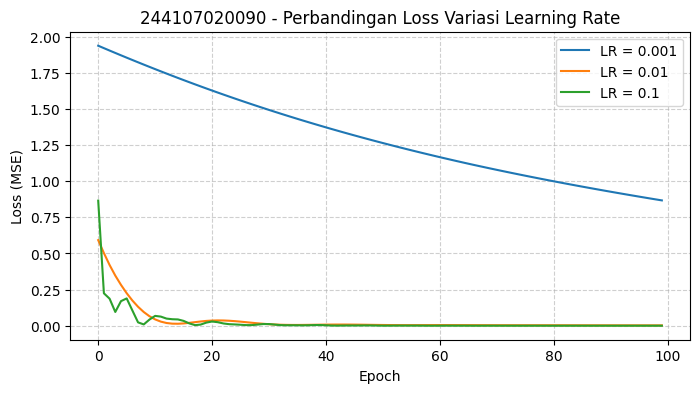

In [ ]:
import matplotlib.pyplot as plt

# Menampilkan Tabel Ringkasan Perbandingan Loss
print("--- Ringkasan Perbandingan Loss (100 Epoch) ---")
for lr_val, loss_val in final_losses_lr.items():
    print(f"LR = {lr_val:<5} | Final MSE Loss = {loss_val:.6f}")

# Visualisasi Kurva Penurunan Loss Untuk Setiap Learning Rate
plt.figure(figsize=(8, 4))
for lr_val, loss_hist in histories_lr.items():
    plt.plot(loss_hist, label=f'LR = {lr_val}')

plt.title('244107020090 - Perbandingan Loss Variasi Learning Rate')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Perubahan learning rate mengatur seberapa besar langkah pembaruan bobot pada setiap iterasi gradient descent. Nilai yang terlalu kecil (0.001) menurunkan loss secara lambat dan halus sehingga dalam 100 epoch sering kali belum mencapai titik minimum optimal, nilai moderat (0.01) umumnya memberikan penurunan loss paling cepat dan stabil mendekati nol, sedangkan nilai yang terlalu besar (0.1) dapat menyebabkan overshooting di mana kurva loss berosilasi atau gagal menetap di titik error terendah.

### Praktikum 4

Langkah 1 - Load Dataset Boston

In [ ]:
from sklearn.metrics import mean_squared_error

# Memuat Dataset Boston Housing Dari Keras (Pengganti load_boston Sklearn Yang Dihapus)
(X_tr_raw, y_tr_raw), (X_te_raw, y_te_raw) = tf.keras.datasets.boston_housing.load_data()

# Menggabungkan Kembali Menjadi Dataset Utuh (506 Sampel, 13 Fitur) Sesuai Alur Modul
X_boston = np.vstack((X_tr_raw, X_te_raw))
y_boston = np.concatenate((y_tr_raw, y_te_raw))

print(f"Bentuk Fitur (X_boston) : {X_boston.shape}")
print(f"Bentuk Target (y_boston): {y_boston.shape}")

Bentuk Fitur (X_boston) : (506, 13)
Bentuk Target (y_boston): (506,)


Langkah 2 - Preprocessing (Standardisasi & Split Data)

In [ ]:
# Normalisasi Fitur Menggunakan StandardScaler
scaler_boston = StandardScaler()
Xs_boston = scaler_boston.fit_transform(X_boston)

# Membagi Data Menjadi Training (80%) Dan Validation (20%)
X_train_b, X_val_b, y_train_b, y_val_b = train_test_split(
    Xs_boston, y_boston, test_size=0.2, random_state=42
)

print(f"Data Latih (X_train_b)  : {X_train_b.shape}")
print(f"Data Validasi (X_val_b) : {X_val_b.shape}")

Data Latih (X_train_b)  : (404, 13)
Data Validasi (X_val_b) : (102, 13)


Langkah 3 - Membangun dan Kompilasi Model MLP

In [ ]:
# Mengatur Seed Untuk Konsistensi Hasil
tf.random.set_seed(42)

# Membangun Arsitektur MLP Regresi
model_boston = tf.keras.Sequential([
    tf.keras.layers.Dense(64, activation='relu', input_shape=(X_train_b.shape[1],)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1)
])

# Kompilasi Model Dengan Optimizer Adam, Loss MSE, Dan Metrik MAE
model_boston.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='mse',
    metrics=['mae']
)

model_boston.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_25 (Dense)                │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,009 (11.75 KB)

 Trainable params: 3,009 (11.75 KB)

 Non-trainable params: 0 (0.00 B)

Langkah 4 - Melatih Model (Training)

In [ ]:
print("Memulai Pelatihan Model MLP Regresi Boston (200 Epoch)...")

# Melatih Model Dengan Data Validasi
h_boston = model_boston.fit(
    X_train_b, y_train_b,
    validation_data=(X_val_b, y_val_b),
    epochs=200,
    batch_size=32,
    verbose=0  # Ubah Menjadi 1 Jika Ingin Melihat Log Setiap Epoch
)

print("Pelatihan Selesai!")
print(f"Train Loss (MSE) Akhir : {h_boston.history['loss'][-1]:.4f} | Val Loss (MSE) Akhir : {h_boston.history['val_loss'][-1]:.4f}")
print(f"Train MAE Akhir        : {h_boston.history['mae'][-1]:.4f}  | Val MAE Akhir        : {h_boston.history['val_mae'][-1]:.4f}")

Memulai Pelatihan Model MLP Regresi Boston (200 Epoch)...
Pelatihan Selesai!
Train Loss (MSE) Akhir : 3.8548 | Val Loss (MSE) Akhir : 26.3031
Train MAE Akhir        : 1.4305  | Val MAE Akhir        : 3.0773


Langkah 5 - Visualisasi Kurva Loss/MAE & Evaluasi RMSE

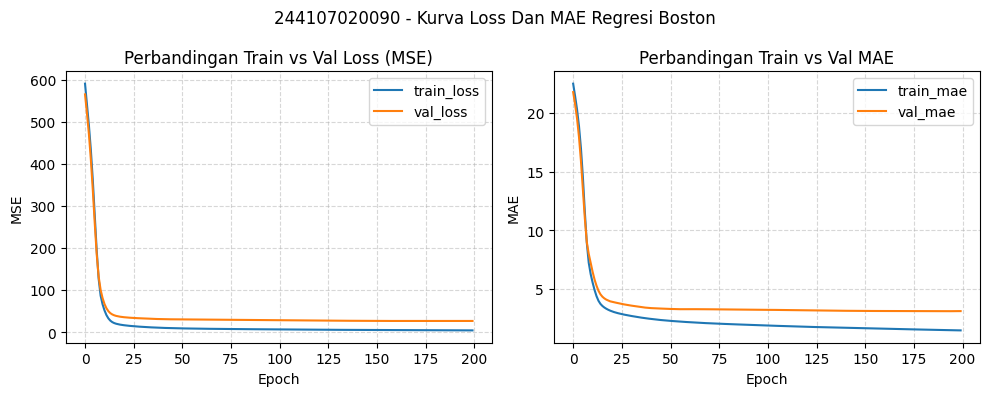


RMSE pada data validasi: 5.1286


In [ ]:
# Visualisasi Riwayat Training Dan Validasi (Loss & MAE)
plt.figure(figsize=(10, 4))
plt.suptitle('244107020090 - Kurva Loss Dan MAE Regresi Boston')

# Subplot 1: Grafik Loss (MSE)
plt.subplot(1, 2, 1)
plt.plot(h_boston.history['loss'], label='train_loss')
plt.plot(h_boston.history['val_loss'], label='val_loss')
plt.title('Perbandingan Train vs Val Loss (MSE)')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Grafik MAE
plt.subplot(1, 2, 2)
plt.plot(h_boston.history['mae'], label='train_mae')
plt.plot(h_boston.history['val_mae'], label='val_mae')
plt.title('Perbandingan Train vs Val MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Prediksi Pada Data Validasi Dan Perhitungan RMSE
pred_boston = model_boston.predict(X_val_b, verbose=0)
rmse_boston = np.sqrt(mean_squared_error(y_val_b, pred_boston))
print(f"\nRMSE pada data validasi: {rmse_boston:.4f}")

Penggunaan dua hidden layer (64 dan 32 neuron) mampu menangkap hubungan non-linear dari 13 variabel lingkungan dan properti pada data Boston Housing secara jauh lebih efektif dibandingkan model linier sederhana. Nilai RMSE hasil akar kuadrat dari MSE mengembalikan satuan kesalahan ke skala harga asli target (dalam ribuan dolar AS), sedangkan perbandingan kurva train_loss terhadap val_loss memudahkan kita mendeteksi apakah model mengalami overfitting (ditandai saat train_loss terus turun namun val_loss mulai stagnan atau naik).